# 04 · EMT-TF Expression (unconditional final step)

The EMT-transcription-factor readout is produced for every dataset regardless of gate outcomes; here
it is the **last** notebook (Gate 2 GO / Gate 3 NA -> deliverable set is 01–03 + expression, numbered
04). Score a broadened EMT-TF panel (Snail/Zeb/Twist **plus** the FOXC and PRRX mesenchymal families,
per the Kürten eval rule) on this dataset, **gated on detectable expression**, and overlay the
root-end and terminus-end factors on the manifold. Deliverable: `expression.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load manifold + score EMT-TF panel along pseudotime
Detection-gated: keep only TFs expressed in >3% of cells. Rank by Spearman correlation with
pseudotime to find the root-end (early) and terminus-end (late) factors.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetection-gated (>3%): {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

cells: 10512 | pseudotime 0.0 -> 8.28
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.116       0.068      0.041    -0.045    EARLY(root)
 PRRX1      0.021       0.017      0.007    -0.037    EARLY(root)
TWIST1      0.000       0.000      0.000    -0.011 LATE(terminus)
 SNAI2      0.005       0.002      0.002    -0.008 LATE(terminus)
  ZEB1      0.008       0.004      0.003    -0.008    EARLY(root)
 SNAI1      0.028       0.009      0.007    -0.001    EARLY(root)
TWIST2      0.008       0.002      0.003     0.015 LATE(terminus)
 FOXC2      0.004       0.001      0.001     0.020 LATE(terminus)
  ZEB2      0.022       0.008      0.008     0.025 LATE(terminus)
 PRRX2      0.082       0.027      0.043     0.070 LATE(terminus)

detection-gated (>3%): ['FOXC1', 'PRRX2']
derived pair: FOXC1 (early/root) <-> PRRX2 (late/terminus)


### EMT-TF overlay (deliverable)
House categorical overlay: thresholded expressers (upper quartile among expressing cells) of the
early and late factor coloured over a grey manifold; `figsize=(3.5,1.5)`, `size=30`.

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.605, 'PRRX2': 0.492} | cells shown: {'FOXC1': 305, 'PRRX2': 216}
FOXC1: 11.6% expressing; 305 shown, mean pseudotime of shown = 0.31 (all = 0.44)
PRRX2: 8.2% expressing; 216 shown, mean pseudotime of shown = 0.52 (all = 0.44)
saved expression.pdf


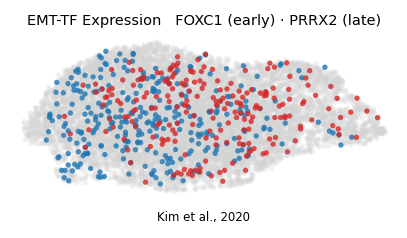

In [4]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) · {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown, '
          f'mean pseudotime of shown = {tn[m].mean():.2f} (all = {tn.mean():.2f})')
print('saved expression.pdf')